# Bài 1 — Logistic Regression bằng NumPy

Phân loại chữ số 0 và 1 trên MNIST.

## 1. Đọc và chuẩn hóa dữ liệu

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if (ROOT / 'Lab2_du_lieu_MNIST').is_dir():
    ROOT = ROOT / 'Lab2_du_lieu_MNIST'

data = np.load(ROOT / 'data' / 'mnist.npz')
X_train = data['X_train']
X_test = data['X_test']
y_train = data['y_train']
y_test = data['y_test']

train_mask = (y_train == 0) | (y_train == 1)
test_mask = (y_test == 0) | (y_test == 1)
X_train = X_train[train_mask]
X_test = X_test[test_mask]
y_train = y_train[train_mask]
y_test = y_test[test_mask]

X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0
output = ROOT / 'results' / 'bai1_logistic_numpy'
output.mkdir(parents=True, exist_ok=True)

## 2. Hàm sigmoid và loss

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def loss_function(y, p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

## 3. Huấn luyện bằng Gradient Descent

In [3]:
w = np.zeros(X_train.shape[1], dtype=np.float32)
b = 0.0
learning_rate = 0.1
epochs = 500
losses = [float(loss_function(y_train, sigmoid(X_train @ w + b)))]

for epoch in range(epochs):
    p = sigmoid(X_train @ w + b)
    error = p - y_train
    dw = X_train.T @ error / len(X_train)
    db = np.mean(error)
    w = w - learning_rate * dw
    b = b - learning_rate * db

    p = sigmoid(X_train @ w + b)
    loss = loss_function(y_train, p)
    losses.append(float(loss))

## 4. Đồ thị loss

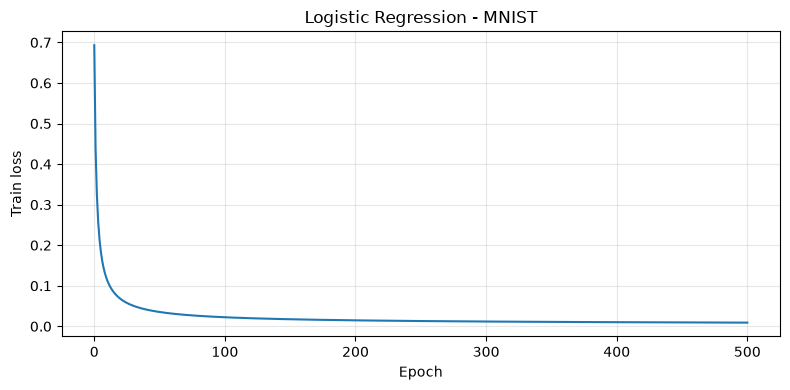

In [4]:
plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('Train loss')
plt.title('Logistic Regression - MNIST')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(output / 'training_loss.png', dpi=160)
plt.show()

## 5. Dự đoán và đánh giá

In [5]:
probabilities = sigmoid(X_test @ w + b)
y_pred = (probabilities >= 0.5).astype(int)
n_classes = 2

cm = np.zeros((n_classes, n_classes), dtype=int)
for i in range(len(y_test)):
    cm[y_test[i], y_pred[i]] += 1

accuracy = float(np.mean(y_test == y_pred))
rows = []
scores = []
print('Lớp   Precision   Recall      F1      Support')
for c in range(n_classes):
    tp = int(cm[c, c])
    fp = int(cm[:, c].sum()) - tp
    fn = int(cm[c, :].sum()) - tp
    support = int(cm[c, :].sum())
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    print(f'{c:3d}   {precision:9.4f}   {recall:6.4f}   {f1:6.4f}   {support:5d}')
    scores.append([precision, recall, f1])
    rows.append({'label': c, 'precision': precision, 'recall': recall,
                 'f1': f1, 'support': support})

macro = np.mean(scores, axis=0)
print('Accuracy:', round(accuracy, 4))
print('Macro Precision:', round(float(macro[0]), 4))
print('Macro Recall:', round(float(macro[1]), 4))
print('Macro F1:', round(float(macro[2]), 4))
print('Ma trận nhầm lẫn:')
print(cm)

Lớp   Precision   Recall      F1      Support
  0      1.0000   0.9980   0.9990     980
  1      0.9982   1.0000   0.9991    1135
Accuracy: 0.9991
Macro Precision: 0.9991
Macro Recall: 0.999
Macro F1: 0.999
Ma trận nhầm lẫn:
[[ 978    2]
 [   0 1135]]


## 6. Lưu kết quả

In [6]:
metrics = {'accuracy': accuracy, 'per_class': rows, 'confusion_matrix': cm.tolist(),
           'macro_precision': float(macro[0]), 'macro_recall': float(macro[1]),
           'macro_f1': float(macro[2]), 'learning_rate': learning_rate, 'epochs': epochs,
           'train_samples': len(y_train), 'test_samples': len(y_test),
           'initial_train_loss': losses[0], 'final_train_loss': losses[-1]}
(output / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
np.savetxt(output / 'training_loss.csv', np.column_stack([np.arange(len(losses)), losses]),
           delimiter=',', header='epoch,train_loss', comments='')
np.savetxt(output / 'test_predictions.csv', np.column_stack([y_test, y_pred]),
           delimiter=',', header='true_label,predicted_label', comments='', fmt='%d')
np.savez(output / 'model.npz', w=w, b=b)